# 03 — Gradient boosting vs random forest, calibration, SHAP

**Random forest**: many deep trees, each trained on a bootstrap sample, then averaged. It's robust and hard to
break, but its probabilities are often squashed toward 50 %.

**Gradient boosting (LightGBM)**: many *shallow* trees built one after another, each fixing the previous ones'
errors. It's usually the strongest model on tabular data, and it handles NaN natively and finds interactions
(e.g. "first-timer *and* off-role"). It also overfits easily on small, noisy data like ours. So:
* small trees (`num_leaves=7`), a low learning rate, row/column subsampling, and L2 regularisation;
* **early stopping** on a slice held out from the end of TRAIN (never on validation);
* compare against the LR baseline from notebook 02 on the same validation games.

**Calibration**: if a model says 70 % but blue wins 60 % of those games, we refit a small mapping (Platt =
logistic on the score) on held-out data. **SHAP** splits each prediction into per-feature contributions, like the
LR explanation but for trees.

In [1]:
# Setup: works locally (Jupyter started in the repo or in training/) and on Google Colab.
import os, sys, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/oracle-training")   # <- the folder you uploaded (see training/README.md)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lightgbm", "shap"], check=True)
else:
    ROOT = Path.cwd() if (Path.cwd() / "trainlib.py").exists() else Path.cwd() / "training"
sys.path.insert(0, str(ROOT))

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import trainlib as tl

# Known harmless library notices (kept out of the saved outputs):
warnings.filterwarnings("ignore", message=".*eval_set.*deprecated")              # LightGBM 4.7 rename; old name works everywhere
warnings.filterwarnings("ignore", message="IProgress not found")                  # shap's progress bar widget
warnings.filterwarnings("ignore", message="LightGBM binary classifier with TreeExplainer")

SEED = 42   # passed as random_state to every model, so runs are reproducible
pd.set_option("display.width", 160, "display.max_columns", 40)

b = tl.load(os.environ.get("ORACLE_BUNDLE", ROOT / "data"))   # newest bundle in data/
print(b.describe())
if len(b.matches) < 500:
    print(f"\n!! Only {len(b.matches)} games: numbers below are mostly noise. Treat this run as a pipeline check "
          "and re-run after more crawling.")

win_v1@548a7d0e28  built 2026-11-05T11:29:28+00:00
rows: 42 matches, 420 seats (skipped: {'incomplete_history': 40})
time: ['2026-06-24T14:55+00:00', '2026-10-20T17:45+00:00']
patches: 16.13, 16.15, 16.17, 16.18, 16.19, 16.20
features: 102 match-level, 32 per seat

!! Only 42 games: numbers below are mostly noise. Treat this run as a pipeline check and re-run after more crawling.


In [2]:
# Columns that have at least some values in TRAIN (rank/mastery are all-empty until clean snapshots exist).
def usable(cols, df):
    return [c for c in cols if df[c].notna().any() and df[c].nunique(dropna=True) > 1]

split = tl.time_split(b.matches, val=0.15, test=0.15, embargo_h=1)
print(split)
ALL = usable(b.features, split.train)
print(f"{len(ALL)} usable features of {len(b.features)}")

# The last 20 % of TRAIN (by time) is used for early stopping and calibration; models fit on the rest.
cut = int(len(split.train) * 0.8)
fit_part, tail = split.train.iloc[:cut], split.train.iloc[cut:]
Xf, yf = fit_part[ALL], fit_part["y_blue_win"]
Xt, yt = tail[ALL], tail["y_blue_win"]
Xv, yv = split.val[ALL], split.val["y_blue_win"]

train    29 rows  2026-06-24 .. 2026-10-05  blue win 0.517
val       6 rows  2026-10-09 .. 2026-10-11  blue win 0.500
test      7 rows  2026-10-12 .. 2026-10-20  blue win 0.857
82 usable features of 102


## 1. Reference: constant prior and LR (same recipe as notebook 02)

In [3]:
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

lr = make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(),
                   LogisticRegression(C=0.03, max_iter=2000)).fit(split.train[ALL], split.train["y_blue_win"])
probs = {"constant": np.full(len(yv), split.train["y_blue_win"].mean()),
         "LR": lr.predict_proba(Xv)[:, 1]}

## 2. Random forest
`min_samples_leaf` stops trees from memorising single games.

In [4]:
from sklearn.ensemble import RandomForestClassifier

rf = make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                   RandomForestClassifier(n_estimators=500, min_samples_leaf=20, max_features="sqrt",
                                          n_jobs=-1, random_state=SEED))
rf.fit(split.train[ALL], split.train["y_blue_win"])
probs["random forest"] = rf.predict_proba(Xv)[:, 1]

## 3. LightGBM with early stopping
Watch `best_iteration_`: if it stops after a handful of trees, the features carry little signal beyond what a
tiny model captures. That's normal for pre-game prediction.

In [5]:
import lightgbm as lgb

gbm = lgb.LGBMClassifier(
    n_estimators=3000, learning_rate=0.02, num_leaves=7, max_depth=3,
    min_child_samples=max(5, min(50, len(fit_part) // 20)),
    subsample=0.8, subsample_freq=1, colsample_bytree=0.7, reg_lambda=5.0,
    random_state=SEED, verbose=-1)
gbm.fit(Xf, yf, eval_set=[(Xt, yt)], eval_metric="binary_logloss",
        callbacks=[lgb.early_stopping(200, verbose=False)])
print("best iteration:", gbm.best_iteration_)
probs["LightGBM"] = gbm.predict_proba(Xv)[:, 1]

best iteration: 14


## 4. Calibrate (Platt scaling on the train tail) and compare everything on validation

skipping calibration: only 6 games in the calibration slice


,n,log_loss,brier,auc,accuracy,vs_first_logloss
model,,,,,,
constant,6,0.6937,0.2503,0.5000,0.5000,0.0000
LR,6,0.6623,0.2345,0.6667,0.6667,-0.0315
random forest,6,0.6934,0.2501,0.5000,0.5000,-0.0003
LightGBM,6,0.7015,0.2541,0.3333,0.5000,0.0078


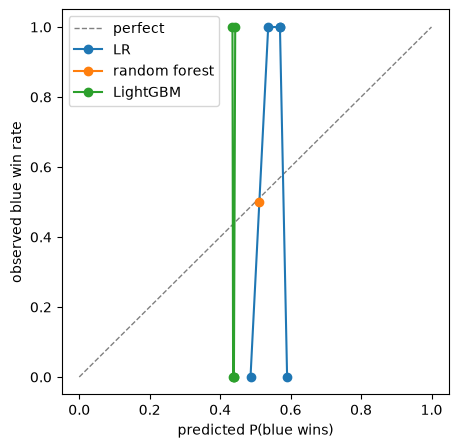

In [6]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator

gbm_cal = None
if yt.value_counts().min() >= 10:   # Platt needs enough wins AND losses in the calibration slice
    gbm_cal = CalibratedClassifierCV(FrozenEstimator(gbm), method="sigmoid").fit(Xt, yt)
    probs["LightGBM + Platt"] = gbm_cal.predict_proba(Xv)[:, 1]
else:
    print(f"skipping calibration: only {len(yt)} games in the calibration slice")

table = tl.compare([tl.evaluate(yv, p, name) for name, p in probs.items()])
display(table)
tl.reliability_plot(yv, {k: v for k, v in probs.items() if k != "constant"}, bins=5); plt.show()

## 5. SHAP: why did the model say that?
* **Beeswarm**: each dot is one game. Its x position is how much that feature pushed P(blue) up or down, and the
  colour is the feature's value.
* **One game**: the top contributions for a single prediction. That's the raw material for "your jungler is the
  problem".

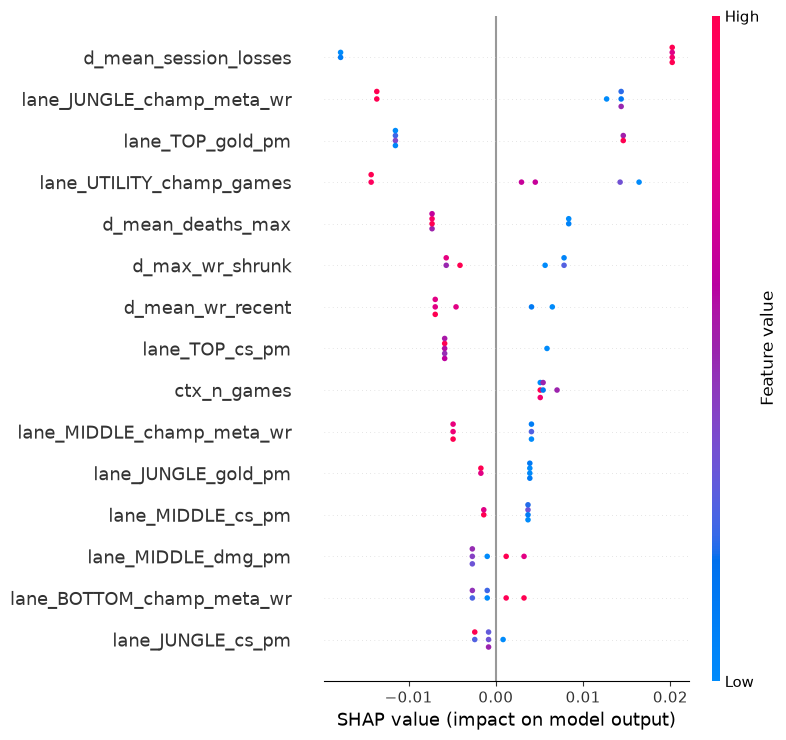

EUN1_4013827046: P(blue) = 43.4%  (actual: 1)


,SHAP (log-odds)
d_mean_session_losses,-0.018
lane_UTILITY_champ_games,0.016
lane_JUNGLE_champ_meta_wr,-0.014
lane_TOP_gold_pm,-0.012
d_mean_deaths_max,0.008
d_max_wr_shrunk,0.008
ctx_n_games,0.007
d_mean_wr_recent,0.006


In [7]:
import shap

explainer = shap.TreeExplainer(gbm)
sv = explainer.shap_values(Xv)
sv = sv[1] if isinstance(sv, list) else sv          # older shap returns [class0, class1]
shap.summary_plot(sv, Xv, max_display=15, show=False); plt.tight_layout(); plt.show()

g = -1
one = pd.Series(sv[g], index=ALL).sort_values(key=abs, ascending=False).head(8)
print(f"{Xv.index[g]}: P(blue) = {probs['LightGBM'][g]:.1%}  (actual: {yv.iloc[g]})")
one.round(3).to_frame("SHAP (log-odds)")

## 6. Ablation: which feature groups earn their place?
Drop one group at a time, refit LightGBM and compare validation log loss. If dropping a group *improves* it, that
group is adding noise at this data size.

In [8]:
groups = {"lane_*": "lane_", "d_min/max_*": ("d_min_", "d_max_"), "ctx_*": "ctx_",
          "champion": ("d_mean_champ", "lane_TOP_champ", "lane_JUNGLE_champ", "lane_MIDDLE_champ",
                       "lane_BOTTOM_champ", "lane_UTILITY_champ")}
rows = [tl.evaluate(yv, probs["LightGBM"], "all features")]
for name, prefixes in groups.items():
    keep = [c for c in ALL if not c.startswith(prefixes)]
    if len(keep) == len(ALL):
        continue
    m = lgb.LGBMClassifier(**gbm.get_params()).fit(
        fit_part[keep], yf, eval_set=[(tail[keep], yt)], callbacks=[lgb.early_stopping(200, verbose=False)])
    rows.append(tl.evaluate(yv, m.predict_proba(split.val[keep])[:, 1], f"without {name}"))
tl.compare(rows)

,n,log_loss,brier,auc,accuracy,vs_first_logloss
model,,,,,,
all features,6,0.7015,0.2541,0.3333,0.5000,0.0000
without lane_*,6,0.7053,0.2560,0.3333,0.5000,0.0038
without d_min/max_*,6,0.7099,0.2580,0.3333,0.6667,0.0083
without ctx_*,6,0.7006,0.2537,0.7778,0.5000,-0.0009
without champion,6,0.7478,0.2771,0.2222,0.1667,0.0463


## 7. Save the best model (pick it on validation, then confirm once on test in notebook 02's style)

In [9]:
best_name = table["log_loss"].idxmin()
best = {"LR": lr, "random forest": rf, "LightGBM": gbm, "LightGBM + Platt": gbm_cal}.get(best_name, lr)
path = tl.save_model(ROOT / "artifacts" / "win_best", best, b, ALL, table.reset_index().to_dict("records"),
                     notes=f"best on validation: {best_name}")
print(f"saved {best_name} to {path}")

saved LR to /Users/tomaspham/Projects/Boosted-Baron/training/artifacts/win_best
